6.  Implement K-Means clustering/ hierarchical clustering on sales_data_sample.csv dataset.  
Determine the number of clusters using the elbow method. 
Dataset link : https://www.kaggle.com/datasets/kyanyoga/sample-sales-data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage


In [2]:
df = pd.read_csv('sales_data_sample.csv', encoding='latin1')

print(df.head())
print(df.shape)
print(df.info())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [3]:
# Select numerical features
X = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES']]

# Normalize the data
sc = StandardScaler()
X_scaled = sc.fit_transform(X)

print(X_scaled[:5])

[[-0.52289086  0.5969775  -0.37082523]
 [-0.11220131 -0.11445035 -0.42789707]
 [ 0.60650538  0.54938372  0.17944282]
 [ 1.01719493 -0.01975856  0.10470098]
 [ 1.42788447  0.81015797  0.89673966]]


c:\Users\sarve\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
c:\Users\sarve\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
c:\Users\sarve\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
c:\Users\sarve\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Win

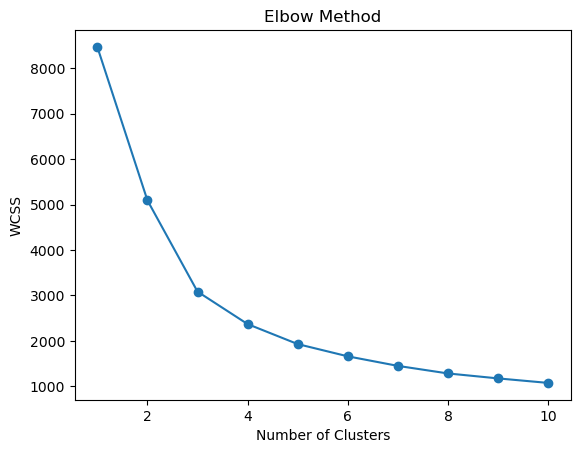

In [4]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print(df[['SALES', 'KMeans_Cluster']].head())
print("K-Means Cluster Counts:")
print(df['KMeans_Cluster'].value_counts())

     SALES  KMeans_Cluster
0  2871.00               2
1  2765.90               2
2  3884.34               1
3  3746.70               1
4  5205.27               1
K-Means Cluster Counts:
KMeans_Cluster
2    1035
1     907
0     881
Name: count, dtype: int64


c:\Users\sarve\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(


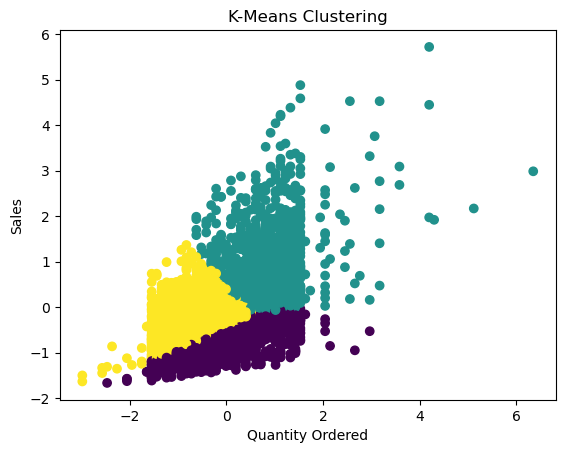

In [6]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 2],
    c=df['KMeans_Cluster']
)

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("K-Means Clustering")
plt.show()

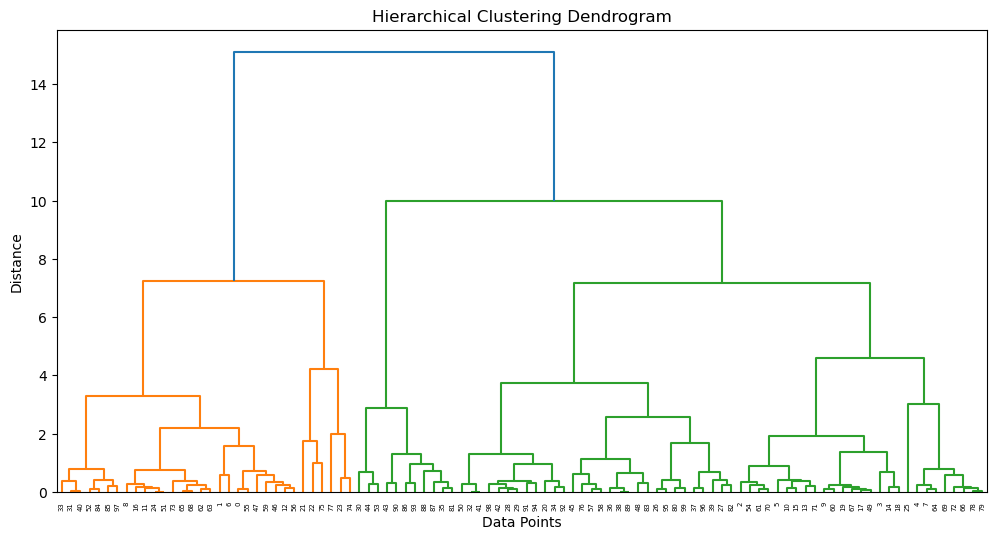

In [7]:
linked = linkage(X_scaled[:100], method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

In [8]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')

df['Hierarchical_Cluster'] = hc.fit_predict(X_scaled)

print(df[['SALES', 'Hierarchical_Cluster']].head())
print("Hierarchical Cluster Counts:")
print(df['Hierarchical_Cluster'].value_counts())

     SALES  Hierarchical_Cluster
0  2871.00                     2
1  2765.90                     2
2  3884.34                     1
3  3746.70                     0
4  5205.27                     1
Hierarchical Cluster Counts:
Hierarchical_Cluster
2    1124
0    1014
1     685
Name: count, dtype: int64


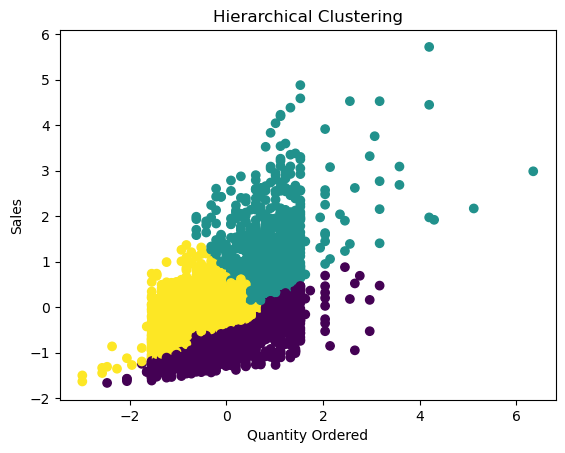

In [9]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 2],
    c=df['Hierarchical_Cluster']
)

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("Hierarchical Clustering")
plt.show()